# Trabalho de IA - Identificação de perfis de consumidores (K-means)

UniEVANGÉLICA - Engenharia de Software - Inteligência Artificial - Turma A
Prof. Lucas Marcos - Tema 17

Dupla: Arthur Victor Rodrigues (2310579) e Sergio Cavalcante (2321154)

Passos: gerar a base, verificar e limpar os dados, padronizar, escolher o k,
treinar o K-means e analisar os grupos.

In [1]:
# bibliotecas
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.decomposition import PCA

SEED = 42  # semente pra dar sempre o mesmo resultado

os.makedirs("dados", exist_ok=True)
os.makedirs("figuras", exist_ok=True)
pd.set_option("display.width", 120)

## 1. Gerando a base de dados

Como não temos dados reais de uma loja, vamos criar 300 clientes fictícios.
Usamos 3 comportamentos diferentes (100 clientes cada):
- clientes que compram bastante e com frequência
- clientes que compram pouco mas gastam muito
- clientes que estão sumidos

A coluna `perfil_gerador` guarda de qual comportamento cada cliente veio, mas ela
**não é usada no treino**, só no final para conferir o resultado.

Também colocamos de propósito 6 linhas duplicadas e 15 valores vazios, para mostrar a limpeza.

In [2]:
rng = np.random.default_rng(SEED)
n = 100

def gerar_clientes(rec_media, rec_desvio, freq_media, ticket_media, ticket_desvio, nome):
    clientes = pd.DataFrame()
    clientes["recencia_dias"] = np.clip(rng.normal(rec_media, rec_desvio, n), 0, 180).round()
    clientes["frequencia_compras"] = np.clip(rng.poisson(freq_media, n), 1, None)
    clientes["ticket_medio_reais"] = np.clip(rng.normal(ticket_media, ticket_desvio, n), 15, None).round(2)
    clientes["perfil_gerador"] = nome
    return clientes

frequentes = gerar_clientes(12, 7, 14, 110, 30, "frequente")
alto_valor = gerar_clientes(50, 18, 4, 380, 70, "alto_valor_ocasional")
inativos = gerar_clientes(125, 30, 2, 55, 18, "inativo")

base = pd.concat([frequentes, alto_valor, inativos], ignore_index=True)
base = base.sample(frac=1, random_state=SEED).reset_index(drop=True)  # embaralha
base.insert(0, "cliente_id", ["C" + str(i).zfill(4) for i in range(1, len(base) + 1)])

# colocando duplicados e valores vazios de propósito
duplicados = base.sample(6, random_state=SEED)
base = pd.concat([base, duplicados], ignore_index=True)

for coluna, qtd in [("recencia_dias", 5), ("frequencia_compras", 4), ("ticket_medio_reais", 6)]:
    linhas = base.sample(qtd, random_state=SEED + qtd).index
    base.loc[linhas, coluna] = np.nan

base.to_csv("dados/clientes_simulados.csv", index=False)
print("Tamanho da base:", base.shape)
print(base.head())

Tamanho da base: (306, 5)
  cliente_id  recencia_dias  frequencia_compras  ticket_medio_reais        perfil_gerador
0      C0001          103.0                 4.0               22.95               inativo
1      C0002           84.0                 3.0               48.09               inativo
2      C0003           37.0                 1.0              301.98  alto_valor_ocasional
3      C0004            6.0                12.0              105.57             frequente
4      C0005          133.0                 1.0               55.53               inativo


## 2. Verificando a base

In [3]:
df = pd.read_csv("dados/clientes_simulados.csv")

print("Total de linhas:", len(df))
print("Linhas duplicadas:", df.duplicated().sum())
print("Valores vazios por coluna:")
print(df.isna().sum())
print(df.describe().round(2))

Total de linhas: 306
Linhas duplicadas: 6
Valores vazios por coluna:
cliente_id            0
recencia_dias         5
frequencia_compras    4
ticket_medio_reais    6
perfil_gerador        0
dtype: int64
       recencia_dias  frequencia_compras  ticket_medio_reais
count         301.00              302.00              300.00
mean           59.69                6.65              183.31
std            48.88                5.78              153.53
min             0.00                1.00               15.00
25%            15.00                2.00               61.62
50%            49.00                4.00              113.00
75%            97.00               11.00              343.53
max           180.00               24.00              576.64


## 3. Limpeza

- tiramos as linhas duplicadas
- preenchemos os vazios com a mediana da coluna (a mediana sofre menos com valores muito altos ou baixos)

In [4]:
colunas = ["recencia_dias", "frequencia_compras", "ticket_medio_reais"]

qtd_antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicados removidos:", qtd_antes - len(df), "| linhas agora:", len(df))

medianas = df[colunas].median()
print("Medianas usadas:")
print(medianas.round(2))

df[colunas] = df[colunas].fillna(medianas)
print("Vazios que sobraram:", int(df[colunas].isna().sum().sum()))

Duplicados removidos: 6 | linhas agora: 300
Medianas usadas:
recencia_dias          48.0
frequencia_compras      4.0
ticket_medio_reais    113.7
dtype: float64
Vazios que sobraram: 0


## 4. Olhando os dados

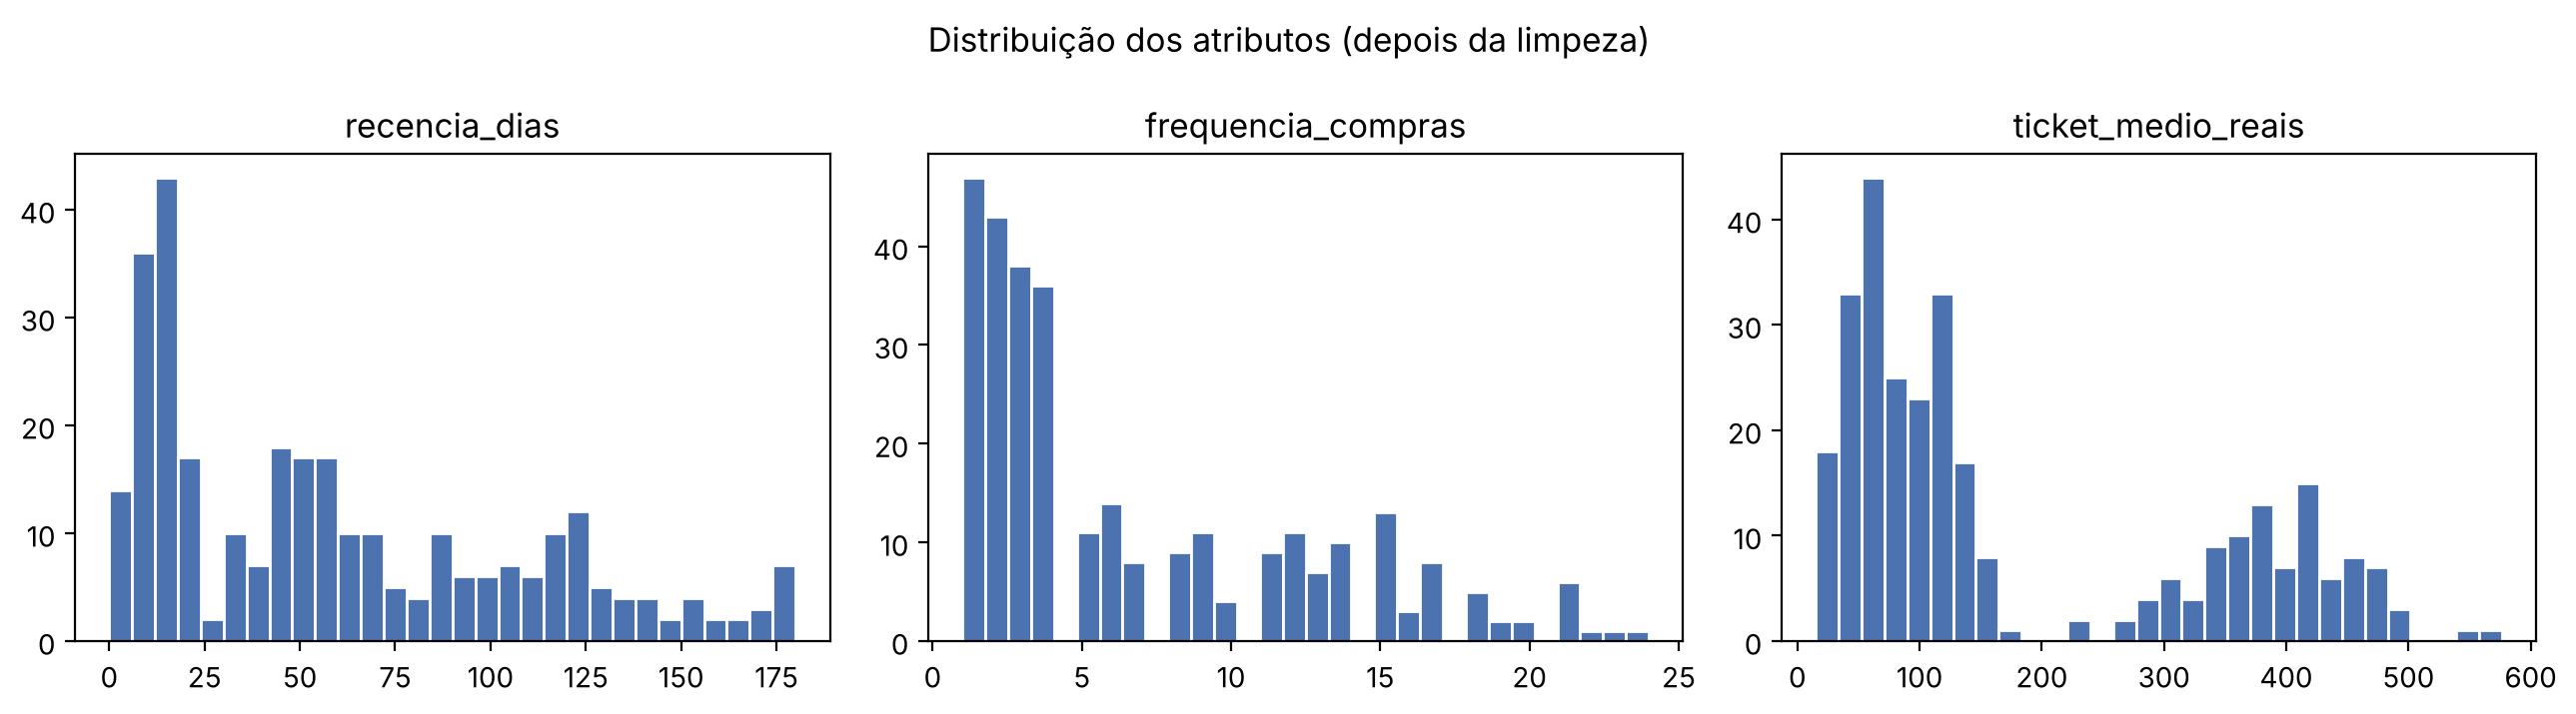

                    recencia_dias  frequencia_compras  ticket_medio_reais
recencia_dias                1.00               -0.65               -0.26
frequencia_compras          -0.65                1.00               -0.21
ticket_medio_reais          -0.26               -0.21                1.00


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for i, col in enumerate(colunas):
    axes[i].hist(df[col], bins=30, color="#4C72B0", edgecolor="white")
    axes[i].set_title(col)
fig.suptitle("Distribuição dos atributos (depois da limpeza)")
fig.tight_layout()
fig.savefig("figuras/01_distribuicoes.png", dpi=150)
plt.show()

# correlação entre os atributos
print(df[colunas].corr().round(2))
# recência e frequência têm correlação negativa: quem compra mais vezes comprou há menos tempo

## 5. Padronização

O K-means usa distância, então precisamos deixar os atributos na mesma escala.
Senão o ticket médio (centenas de reais) pesa muito mais que a frequência.

Fórmula: z = (x - média) / desvio padrão

In [6]:
scaler = StandardScaler()
X = scaler.fit_transform(df[colunas])

print("Média depois de padronizar:", X.mean(axis=0).round(3))
print("Desvio padrão depois de padronizar:", X.std(axis=0).round(3))

Média depois de padronizar: [0. 0. 0.]
Desvio padrão depois de padronizar: [1. 1. 1.]


## 6. Escolhendo o número de grupos (k)

Testamos k de 2 até 6 e olhamos:
- **inércia** (método do cotovelo)
- **silhueta** (quanto mais perto de 1, melhor)

In [7]:
resultados = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=SEED)
    km.fit(X)
    sil = silhouette_score(X, km.labels_)
    resultados.append({"k": k, "inercia": km.inertia_, "silhueta": sil})

tabela_k = pd.DataFrame(resultados)
tabela_k.to_csv("dados/escolha_k.csv", index=False)
print(tabela_k.round(3))

# pega o k com a maior silhueta
melhor_k = int(tabela_k.loc[tabela_k["silhueta"].idxmax(), "k"])
print("Melhor k pela silhueta:", melhor_k)

   k  inercia  silhueta
0  2  495.179     0.464
1  3  163.585     0.650
2  4  126.235     0.555
3  5   96.209     0.488
4  6   83.975     0.492
Melhor k pela silhueta: 3


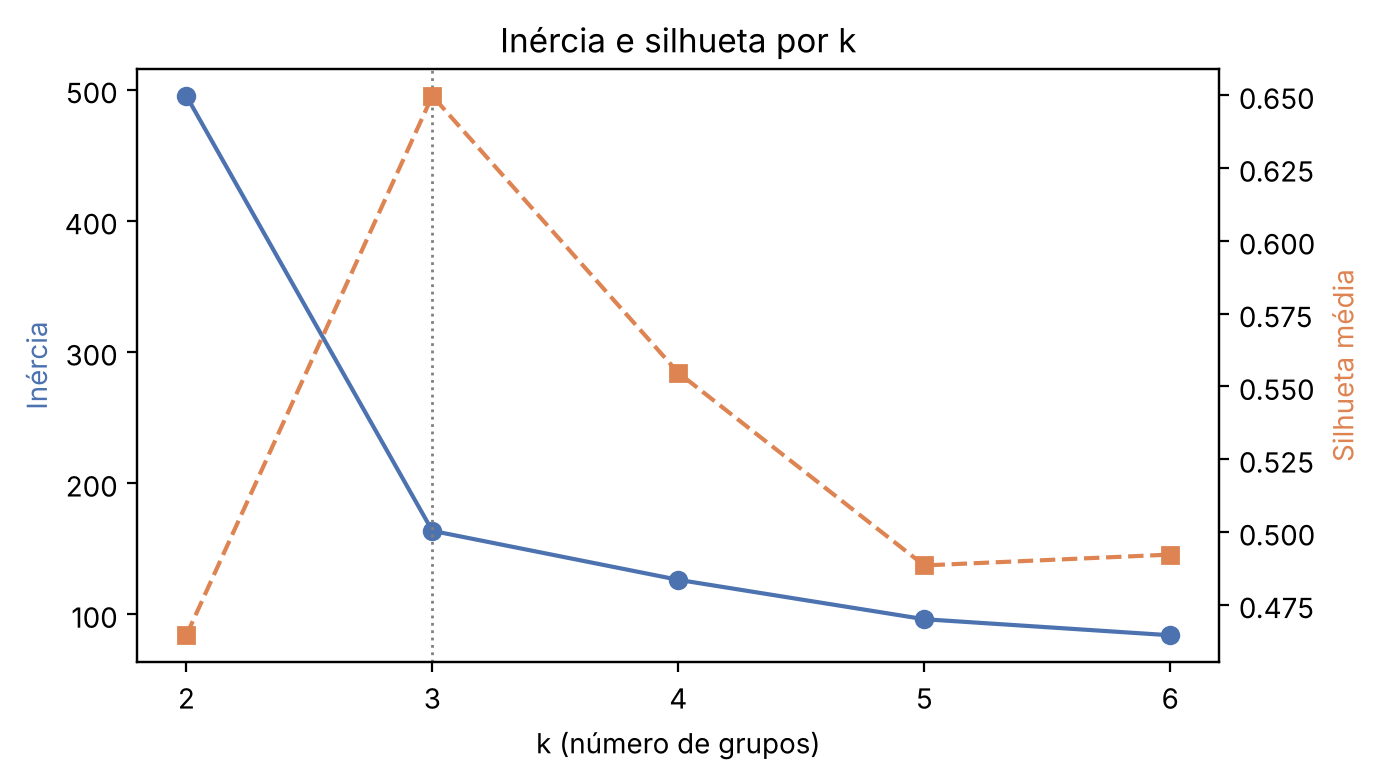

In [8]:
fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(tabela_k["k"], tabela_k["inercia"], "o-", color="#4C72B0")
ax1.set_xlabel("k (número de grupos)")
ax1.set_ylabel("Inércia", color="#4C72B0")
ax1.set_xticks(list(tabela_k["k"]))

ax2 = ax1.twinx()
ax2.plot(tabela_k["k"], tabela_k["silhueta"], "s--", color="#DD8452")
ax2.set_ylabel("Silhueta média", color="#DD8452")

ax1.axvline(melhor_k, color="gray", ls=":", lw=1)
ax1.set_title("Inércia e silhueta por k")
fig.tight_layout()
fig.savefig("figuras/02_escolha_k.png", dpi=150)
plt.show()

Deu k = 3: é onde a silhueta é maior e também onde a inércia para de cair muito (cotovelo).

## 7. Treinando o modelo final

In [9]:
modelo = KMeans(n_clusters=melhor_k, init="k-means++", n_init=10, random_state=SEED)
modelo.fit(X)

df["grupo"] = modelo.labels_
silhueta_final = silhouette_score(X, modelo.labels_)

print("k:", melhor_k)
print("Inércia:", round(modelo.inertia_, 1))
print("Silhueta média:", round(silhueta_final, 3))
print("Iterações até convergir:", modelo.n_iter_)
print("Clientes por grupo:")
print(df["grupo"].value_counts().sort_index())

k: 3
Inércia: 163.6
Silhueta média: 0.65
Iterações até convergir: 3
Clientes por grupo:
grupo
0    102
1    100
2     98
Name: count, dtype: int64


## 8. Testando a estabilidade

Rodamos o K-means de novo com 10 sementes diferentes e comparamos com o modelo final
usando o ARI (Índice de Rand Ajustado). Se der perto de 1, os grupos não mudam.

In [10]:
lista_ari = []
for s in range(10):
    teste = KMeans(n_clusters=melhor_k, init="k-means++", n_init=1, random_state=100 + s)
    rotulos = teste.fit_predict(X)
    lista_ari.append(adjusted_rand_score(modelo.labels_, rotulos))

print("ARI médio:", round(np.mean(lista_ari), 3))
print("ARI mínimo:", round(np.min(lista_ari), 3))

ARI médio: 0.996
ARI mínimo: 0.99


## 9. Entendendo cada grupo

Voltamos os valores para as unidades normais (dias, compras e reais) e usamos a mediana de cada grupo.
Os nomes dos perfis fomos nós que demos, olhando os números.

In [11]:
centroides = pd.DataFrame(scaler.inverse_transform(modelo.cluster_centers_), columns=colunas)

perfil = df.groupby("grupo")[colunas].median().round(1)
perfil["clientes"] = df["grupo"].value_counts().sort_index()
sil_cliente = silhouette_samples(X, modelo.labels_)
perfil["silhueta_media"] = pd.Series(sil_cliente).groupby(df["grupo"]).mean().round(3)

def dar_nome(linha):
    if linha["recencia_dias"] <= 30 and linha["frequencia_compras"] >= 8:
        return "Frequentes"
    elif linha["ticket_medio_reais"] >= 250:
        return "Alto valor ocasional"
    elif linha["recencia_dias"] >= 90:
        return "Inativos / em risco"
    else:
        return "Intermediário"

perfil["perfil"] = perfil.apply(dar_nome, axis=1)
df["perfil"] = df["grupo"].map(perfil["perfil"])

perfil.to_csv("dados/perfis_resultado.csv")
df.to_csv("dados/clientes_com_grupo.csv", index=False)
print(perfil)

       recencia_dias  frequencia_compras  ticket_medio_reais  clientes  silhueta_media                perfil
grupo                                                                                                       
0               12.0                14.0               113.7       102           0.652            Frequentes
1              117.0                 2.0                54.1       100           0.651   Inativos / em risco
2               50.0                 3.0               388.0        98           0.646  Alto valor ocasional


## 10. Gráficos dos grupos

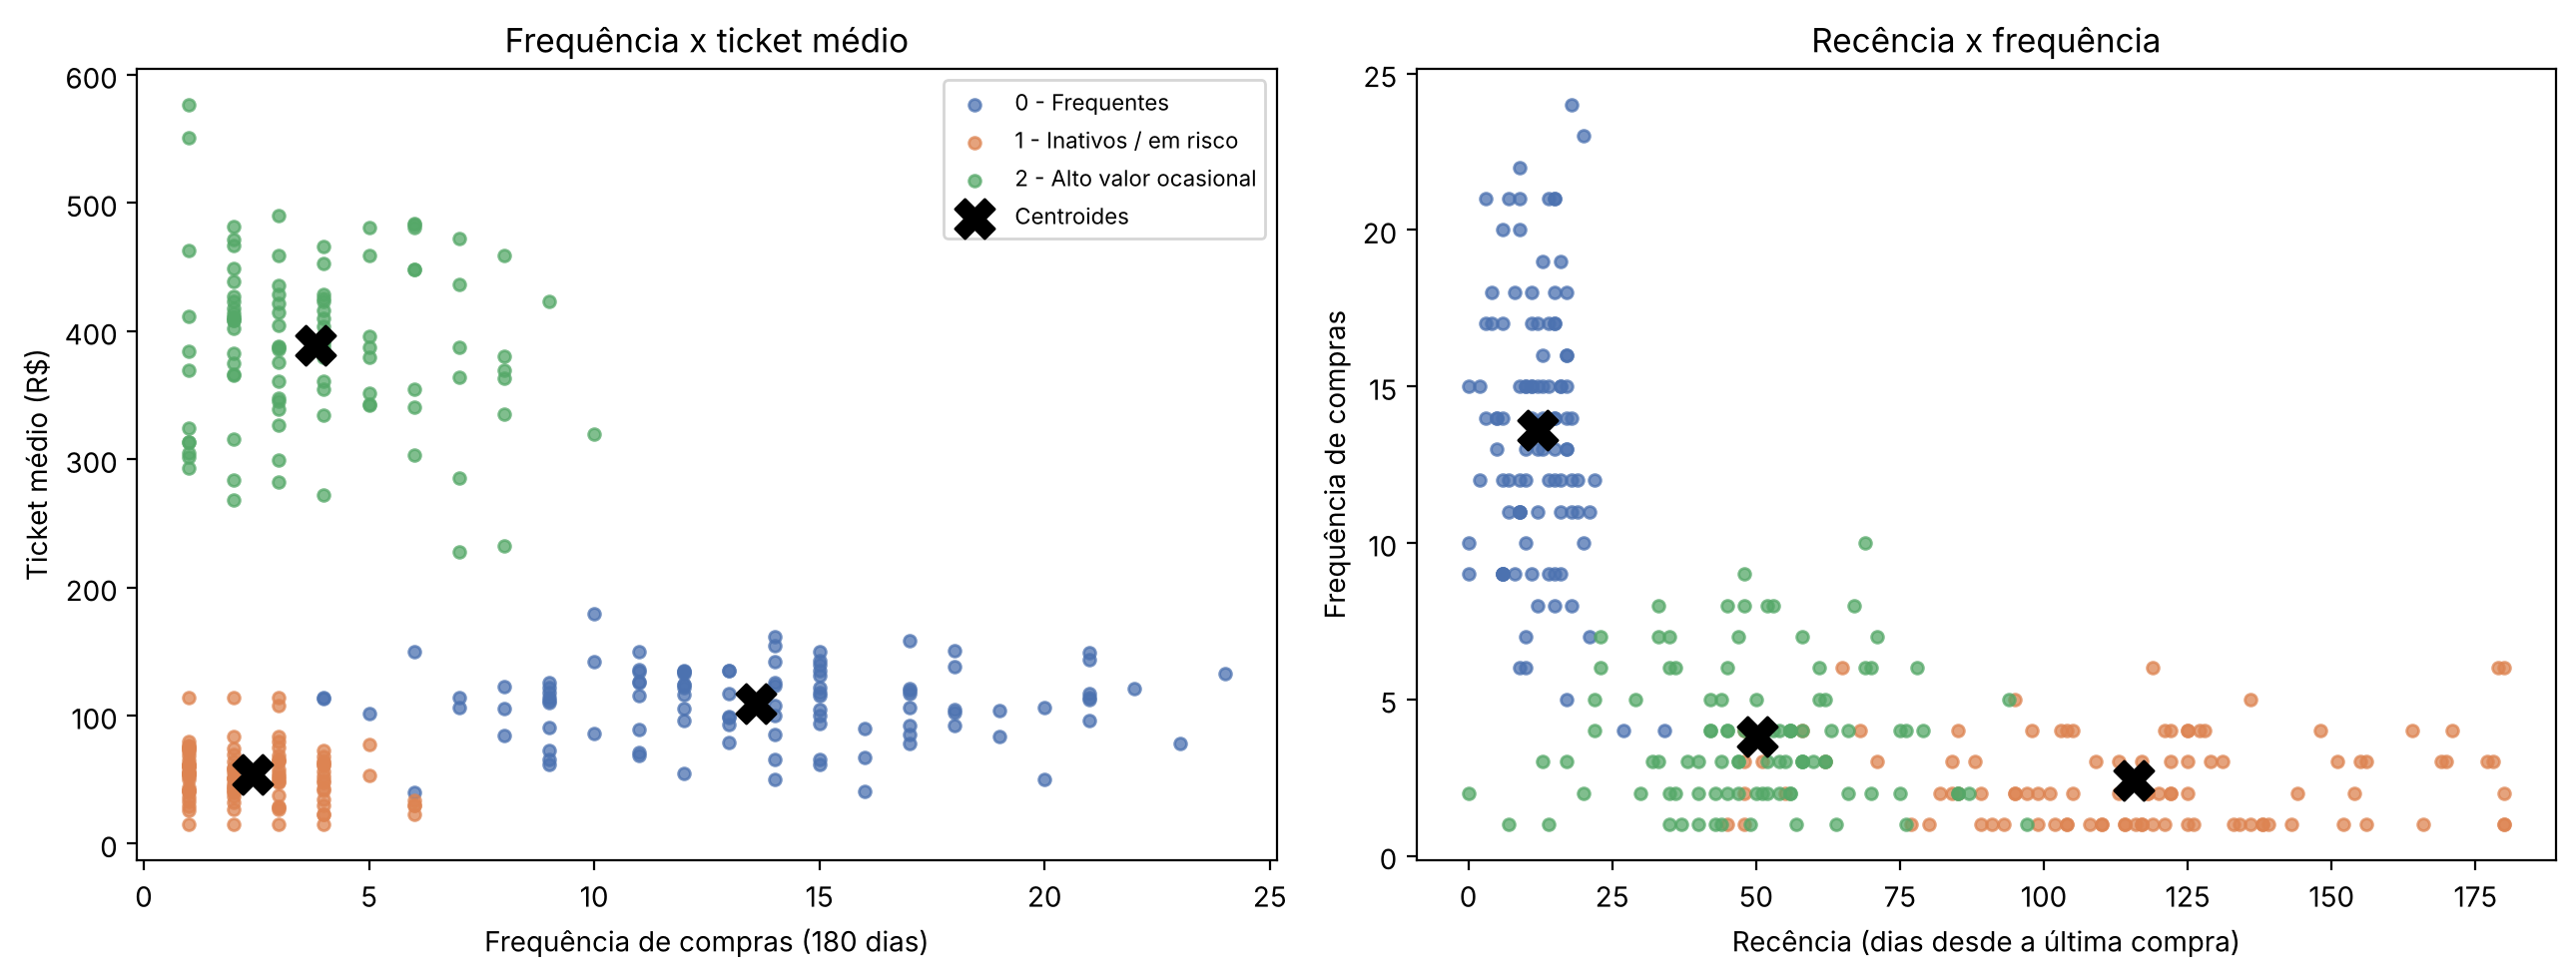

In [12]:
cores = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for g in sorted(df["grupo"].unique()):
    dados_g = df[df["grupo"] == g]
    axes[0].scatter(dados_g["frequencia_compras"], dados_g["ticket_medio_reais"],
                    s=18, alpha=0.75, color=cores[g], label=str(g) + " - " + perfil.loc[g, "perfil"])
axes[0].scatter(centroides["frequencia_compras"], centroides["ticket_medio_reais"],
                marker="X", s=200, color="black", label="Centroides")
axes[0].set_xlabel("Frequência de compras (180 dias)")
axes[0].set_ylabel("Ticket médio (R$)")
axes[0].set_title("Frequência x ticket médio")
axes[0].legend(fontsize=8)

for g in sorted(df["grupo"].unique()):
    dados_g = df[df["grupo"] == g]
    axes[1].scatter(dados_g["recencia_dias"], dados_g["frequencia_compras"], s=18, alpha=0.75, color=cores[g])
axes[1].scatter(centroides["recencia_dias"], centroides["frequencia_compras"], marker="X", s=200, color="black")
axes[1].set_xlabel("Recência (dias desde a última compra)")
axes[1].set_ylabel("Frequência de compras")
axes[1].set_title("Recência x frequência")

fig.tight_layout()
fig.savefig("figuras/03_grupos.png", dpi=150)
plt.show()

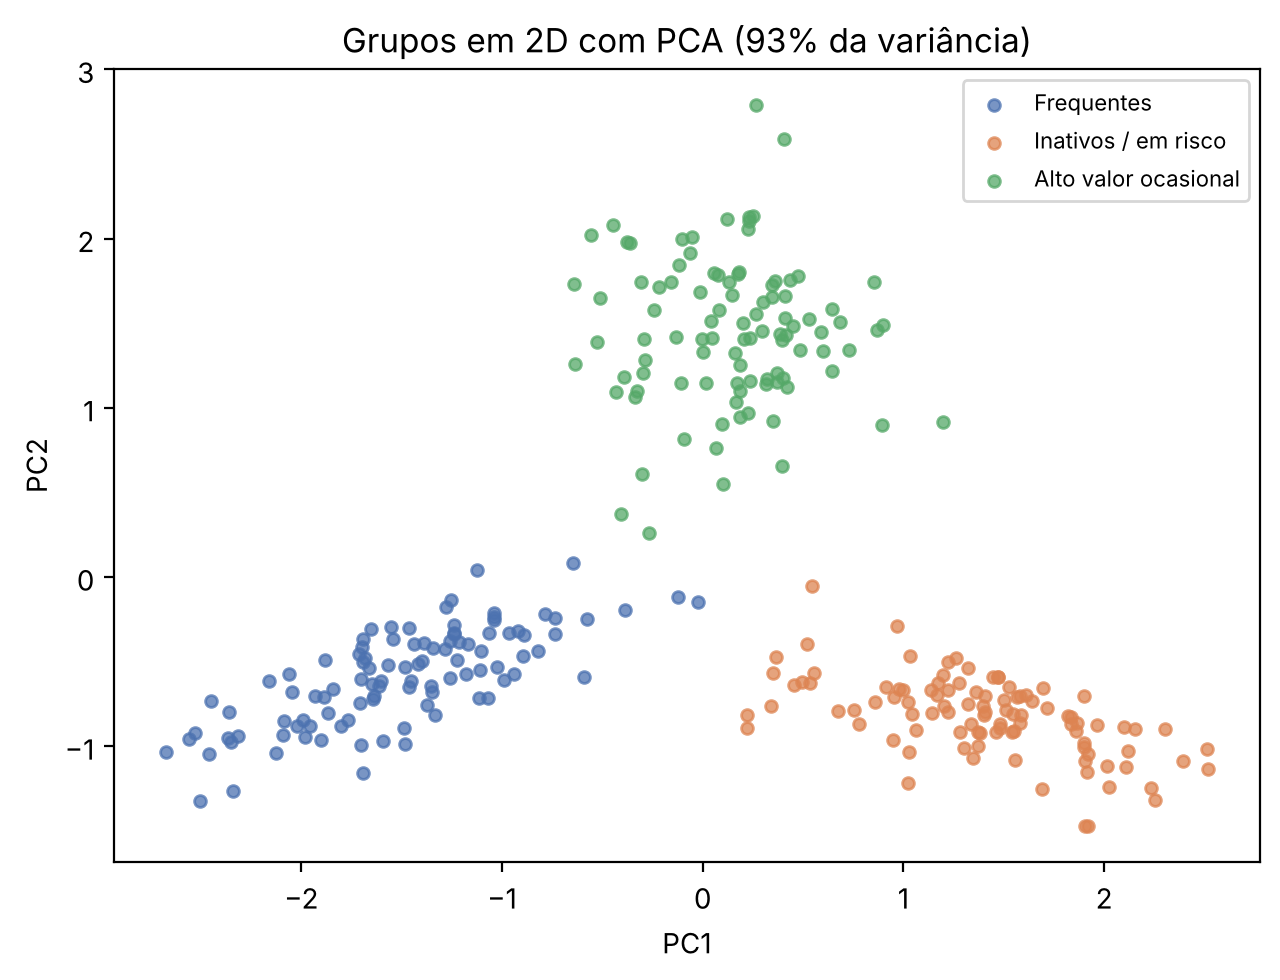

In [13]:
# PCA só pra conseguir ver os 3 atributos em um gráfico 2D
pca = PCA(n_components=2, random_state=SEED)
Z = pca.fit_transform(X)

fig, ax = plt.subplots(figsize=(6.5, 5))
for g in sorted(df["grupo"].unique()):
    m = (df["grupo"] == g).values
    ax.scatter(Z[m, 0], Z[m, 1], s=18, alpha=0.75, color=cores[g], label=perfil.loc[g, "perfil"])
variancia = pca.explained_variance_ratio_.sum() * 100
ax.set_title("Grupos em 2D com PCA (" + str(round(variancia)) + "% da variância)")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("figuras/04_pca.png", dpi=150)
plt.show()

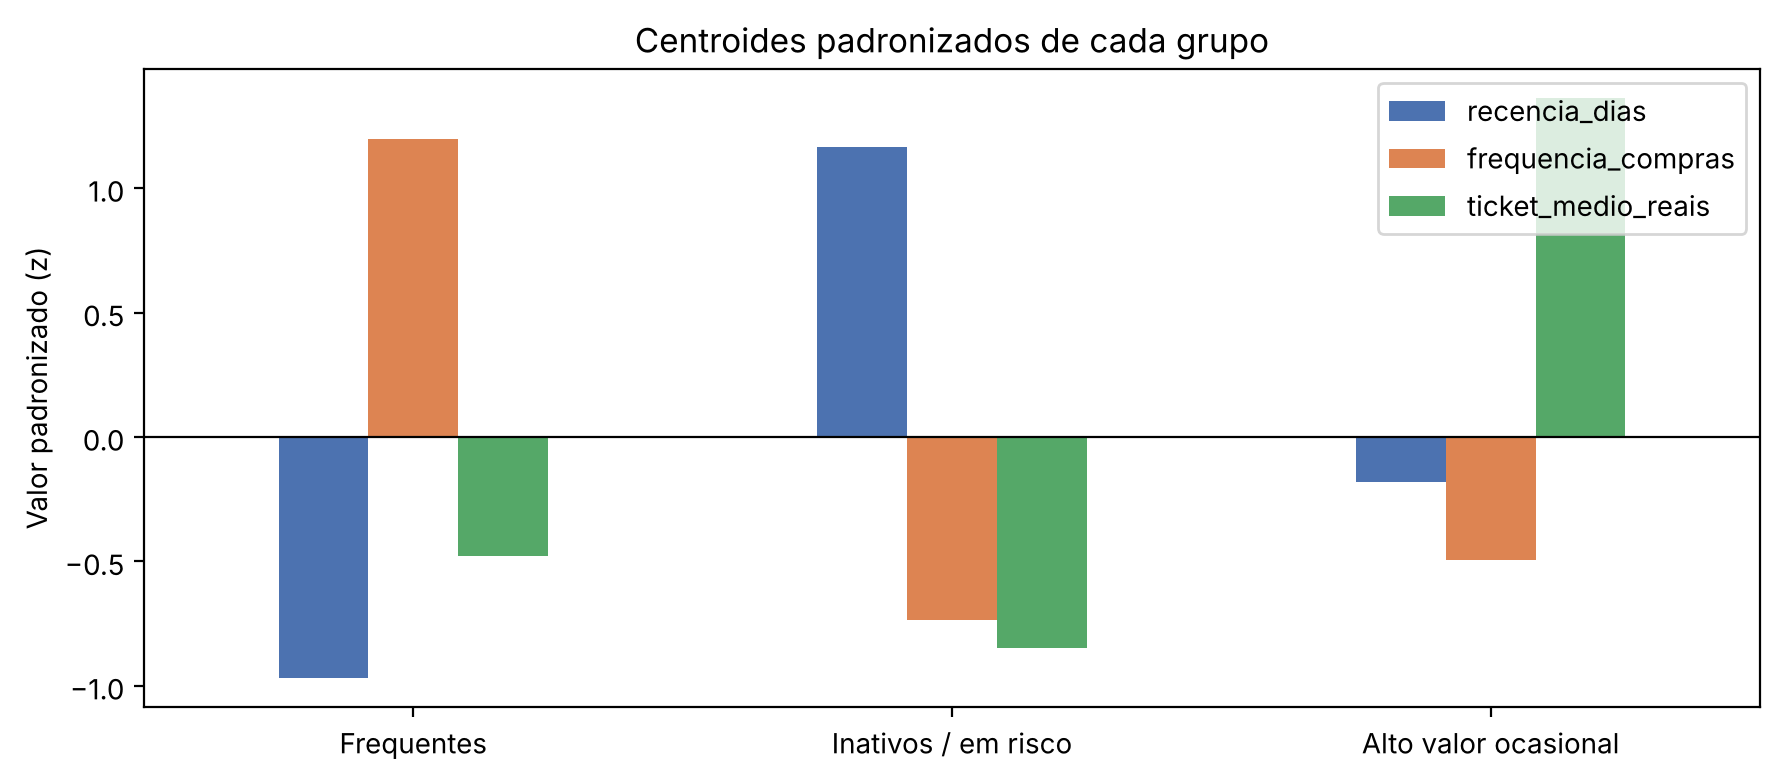

In [14]:
# centroides padronizados: acima de 0 = acima da média, abaixo de 0 = abaixo da média
fig, ax = plt.subplots(figsize=(9, 4))
centroides_z = pd.DataFrame(modelo.cluster_centers_, columns=colunas, index=perfil["perfil"])
centroides_z.plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452", "#55A868"])
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Valor padronizado (z)")
ax.set_xlabel("")
ax.set_title("Centroides padronizados de cada grupo")
plt.xticks(rotation=0)
fig.tight_layout()
fig.savefig("figuras/05_centroides.png", dpi=150)
plt.show()

## 11. Conferindo com a base original

Isso só dá pra fazer porque a base é simulada e sabemos de onde cada cliente veio.
Com dados reais não teria essa "resposta".

In [15]:
print(pd.crosstab(df["perfil"], df["perfil_gerador"]))
print()
print("ARI grupos x perfil de origem:", round(adjusted_rand_score(df["perfil_gerador"], df["grupo"]), 3))

perfil_gerador        alto_valor_ocasional  frequente  inativo
perfil                                                        
Alto valor ocasional                    98          0        0
Frequentes                               2        100        0
Inativos / em risco                      0          0      100

ARI grupos x perfil de origem: 0.98


In [16]:
# quais clientes ficaram no grupo "errado"?
errados = df[(df["perfil"] == "Frequentes") & (df["perfil_gerador"] == "alto_valor_ocasional")]
print(errados)
# os dois estavam com o ticket vazio e receberam a mediana (113,70), por isso foram pro grupo Frequentes

    cliente_id  recencia_dias  frequencia_compras  ticket_medio_reais        perfil_gerador  grupo      perfil
131      C0132           21.0                 7.0             113.695  alto_valor_ocasional      0  Frequentes
187      C0188           34.0                 4.0             113.695  alto_valor_ocasional      0  Frequentes


## 12. Testando com clientes novos

In [17]:
novos = pd.DataFrame({
    "recencia_dias": [5, 60, 150],
    "frequencia_compras": [18, 3, 1],
    "ticket_medio_reais": [95.0, 420.0, 40.0],
})
novos["grupo"] = modelo.predict(scaler.transform(novos[colunas]))
novos["perfil"] = novos["grupo"].map(perfil["perfil"])
print(novos)

   recencia_dias  frequencia_compras  ticket_medio_reais  grupo                perfil
0              5                  18                95.0      0            Frequentes
1             60                   3               420.0      2  Alto valor ocasional
2            150                   1                40.0      1   Inativos / em risco
